In [1]:
# === 1. Imports & Setup ===
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from pathlib import Path

# --- Setup ---
DATA_DIR = Path("../data/analysis-data")

def load_ticker(ticker: str) -> pd.DataFrame:
    """Load TA-enriched CSV for a given ticker."""
    csv_path = DATA_DIR / f"{ticker}.csv"
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    return df

# Default: NG.L
ticker = "NG.L"
df = load_ticker(ticker)
df.index = df["Date"]

# --- Filter to last 10 years ---
cutoff_date = pd.Timestamp("2024-10-15")
df = df[df["Date"] >= cutoff_date].reset_index(drop=True)
df.index = df["Date"]

print(f"Ticker: {ticker}, Rows: {len(df)}, Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

# Use last 200 bars for readability
window = 200
d = df.iloc[-window:].copy()
d.index = d["Date"]  # use Date as index for proper x-axis formatting

# ============================================================
# chart helpers
# ============================================================
def make_ax(figsize=(16, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.xticks(rotation=45)
    return fig, ax

Ticker: NG.L, Rows: 508, Date range: 2024-10-15 to 2026-10-16


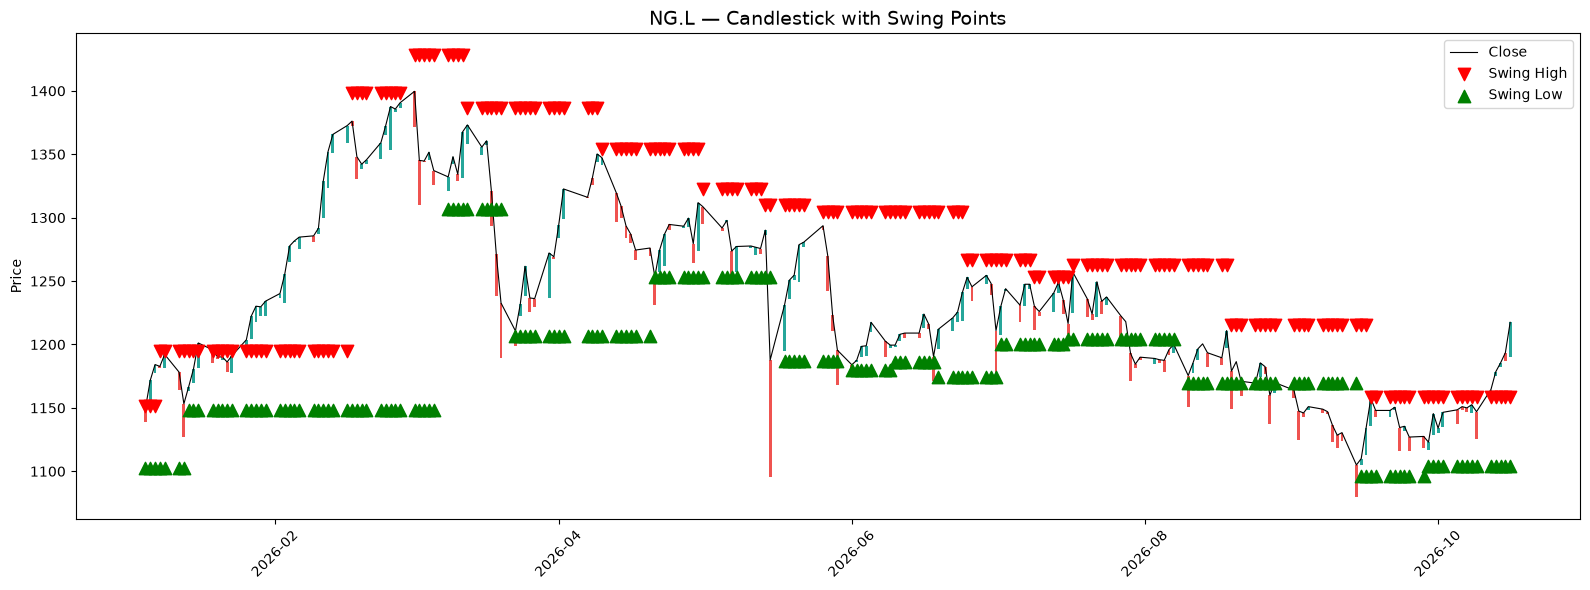

In [2]:
# ============================================================
# CELL 1 — Candlestick with Swing Highs & Lows
# ============================================================
fig, ax = make_ax()

# candlestick
d_up = d["Close"] >= d["Open"]
d_down = ~d_up
ax.bar(d.index[d_up], d["Close"][d_up] - d["Open"][d_up], 0.6,
       bottom=d["Open"][d_up], color="#26a69a")
ax.bar(d.index[d_down], d["Close"][d_down] - d["Open"][d_down], 0.6,
       bottom=d["Close"][d_down], color="#ef5350")
ax.plot(d["Close"], color="black", linewidth=0.8, label="Close")

# swing highs
sh = d["ta_swing_high"].notna()
if sh.any():
    ax.scatter(d.index[sh], d["ta_swing_high"][sh], color="red",
               marker="v", s=80, zorder=5, label="Swing High")

# swing lows
sl = d["ta_swing_low"].notna()
if sl.any():
    ax.scatter(d.index[sl], d["ta_swing_low"][sl], color="green",
               marker="^", s=80, zorder=5, label="Swing Low")

ax.set_title(f"{ticker} — Candlestick with Swing Points", fontsize=14)
ax.legend()
ax.set_ylabel("Price")
plt.tight_layout()
plt.show()

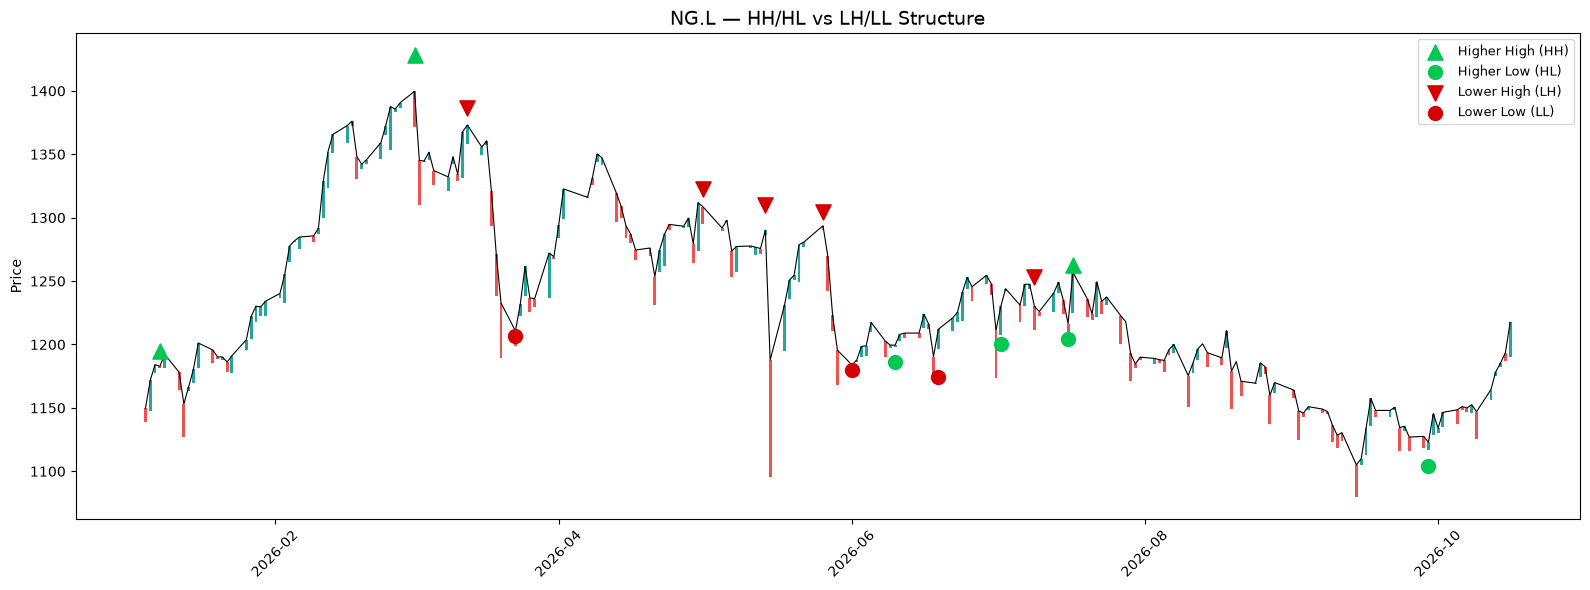

In [3]:
# ============================================================
# CELL 2 — Higher High / Higher Low (Bullish) & Lower High / Lower Low (Bearish)
# ============================================================
fig, ax = make_ax()

# candlestick
d_up = d["Close"] >= d["Open"]
d_down = ~d_up
ax.bar(d.index[d_up], d["Close"][d_up] - d["Open"][d_up], 0.6,
       bottom=d["Open"][d_up], color="#26a69a")
ax.bar(d.index[d_down], d["Close"][d_down] - d["Open"][d_down], 0.6,
       bottom=d["Close"][d_down], color="#ef5350")
ax.plot(d["Close"], color="black", linewidth=0.8)

# HH — green triangles
hh = d["ta_hh"] == 1
if hh.any():
    ax.scatter(d.index[hh], d["High"][hh], color="#00c853",
               marker="^", s=120, zorder=5, label="Higher High (HH)")

# HL — green circles
hl = d["ta_hl"] == 1
if hl.any():
    ax.scatter(d.index[hl], d["Low"][hl], color="#00c853",
               marker="o", s=100, zorder=5, label="Higher Low (HL)")

# LH — red triangles
lh = d["ta_lh"] == 1
if lh.any():
    ax.scatter(d.index[lh], d["High"][lh], color="#d50000",
               marker="v", s=120, zorder=5, label="Lower High (LH)")

# LL — red circles
ll = d["ta_ll"] == 1
if ll.any():
    ax.scatter(d.index[ll], d["Low"][ll], color="#d50000",
               marker="o", s=100, zorder=5, label="Lower Low (LL)")

ax.set_title(f"{ticker} — HH/HL vs LH/LL Structure", fontsize=14)
ax.legend(fontsize=9)
ax.set_ylabel("Price")
plt.tight_layout()
plt.show()

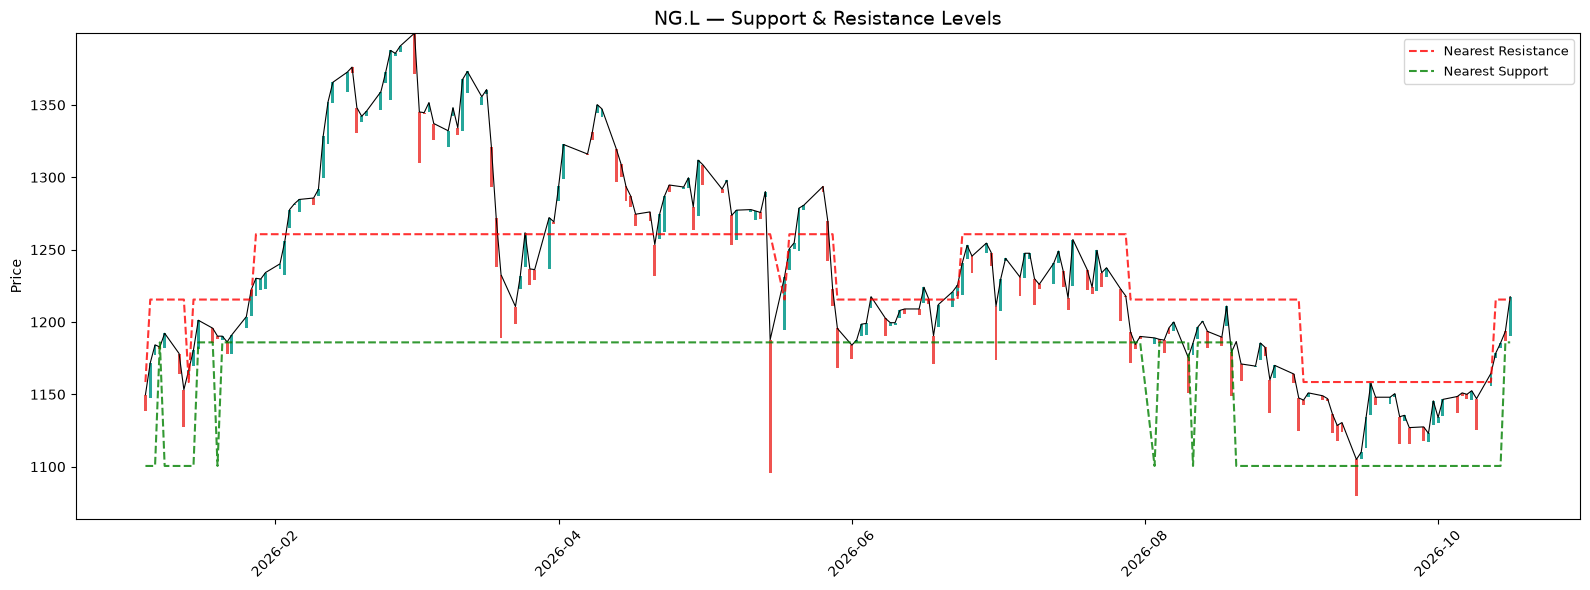

In [4]:
# ============================================================
# CELL 3 — Support & Resistance Levels
# ============================================================
fig, ax = make_ax()

# candlestick
d_up = d["Close"] >= d["Open"]
d_down = ~d_up
ax.bar(d.index[d_up], d["Close"][d_up] - d["Open"][d_up], 0.6,
       bottom=d["Open"][d_up], color="#26a69a")
ax.bar(d.index[d_down], d["Close"][d_down] - d["Open"][d_down], 0.6,
       bottom=d["Close"][d_down], color="#ef5350")
ax.plot(d["Close"], color="black", linewidth=0.8)

# nearest resistance (dashed red)
res = d["ta_nearest_resistance"].notna()
if res.any():
    ax.plot(d.index[res], d["ta_nearest_resistance"][res],
            color="red", linestyle="--", linewidth=1.5, alpha=0.8,
            label="Nearest Resistance")

# nearest support (dashed green)
sup = d["ta_nearest_support"].notna()
if sup.any():
    ax.plot(d.index[sup], d["ta_nearest_support"][sup],
            color="green", linestyle="--", linewidth=1.5, alpha=0.8,
            label="Nearest Support")

ax.set_title(f"{ticker} — Support & Resistance Levels", fontsize=14)
ax.legend(fontsize=9)
ax.set_ylabel("Price")
plt.tight_layout()
plt.show()

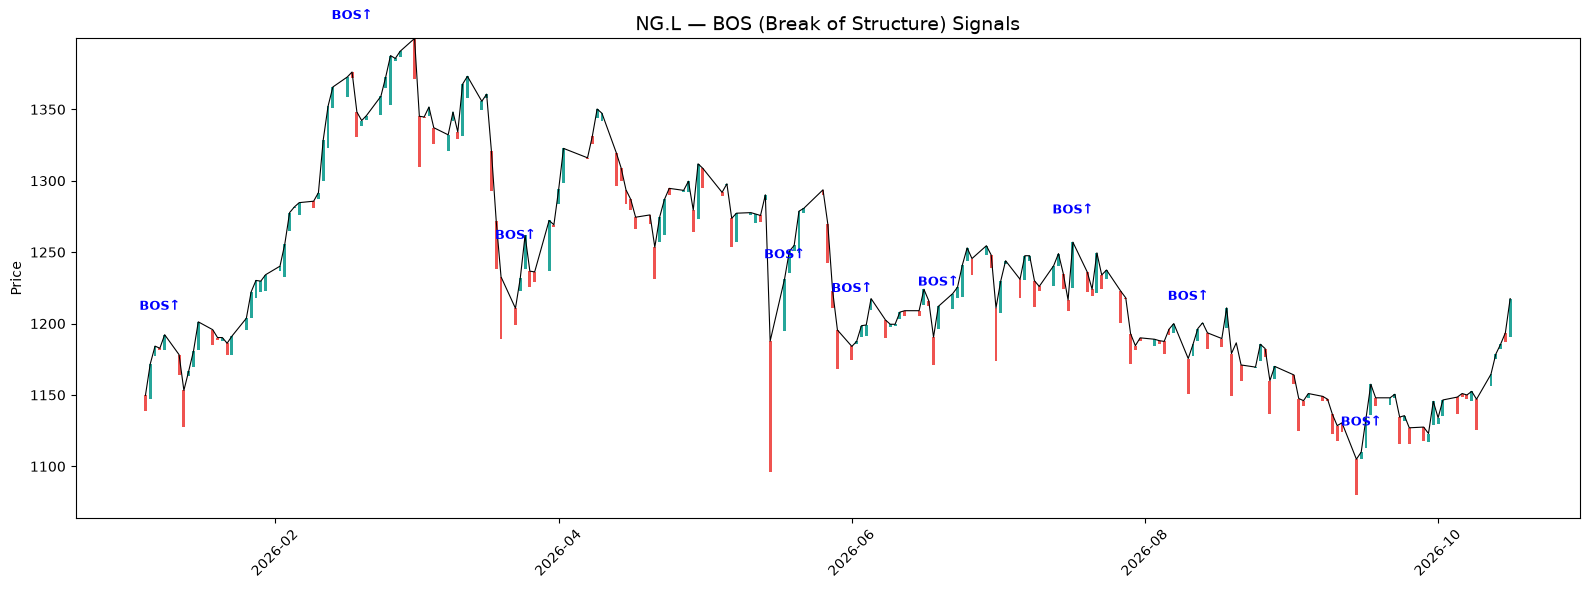

In [5]:
# ============================================================
# CELL 4 — BOS (Break of Structure)
# ============================================================
fig, ax = make_ax()

# candlestick
d_up = d["Close"] >= d["Open"]
d_down = ~d_up
ax.bar(d.index[d_up], d["Close"][d_up] - d["Open"][d_up], 0.6,
       bottom=d["Open"][d_up], color="#26a69a")
ax.bar(d.index[d_down], d["Close"][d_down] - d["Open"][d_down], 0.6,
       bottom=d["Close"][d_down], color="#ef5350")
ax.plot(d["Close"], color="black", linewidth=0.8)

# BOS markers — bullish (up arrow, blue), bearish (need to infer from context)
# ta_bos == 1 at swing high bars = bullish BOS (break above prior HH)
# We'll color based on trend context
bos_idx = d[d["ta_bos"] == 1].index
if len(bos_idx) > 0:
    # For each BOS, check if it's at a swing high (bullish BOS) or swing low (bearish BOS)
    for i in bos_idx:
        if d.loc[i, "ta_swing_high"] is not None:
            ax.annotate("BOS↑", xy=(i, d.loc[i, "High"]),
                        xytext=(0, 15), textcoords="offset points",
                        ha="center", color="blue", fontsize=9, fontweight="bold")
        elif d.loc[i, "ta_swing_low"] is not None:
            ax.annotate("BOS↓", xy=(i, d.loc[i, "Low"]),
                        xytext=(0, -15), textcoords="offset points",
                        ha="center", color="darkorange", fontsize=9, fontweight="bold")

ax.set_title(f"{ticker} — BOS (Break of Structure) Signals", fontsize=14)
ax.set_ylabel("Price")
plt.tight_layout()
plt.show()

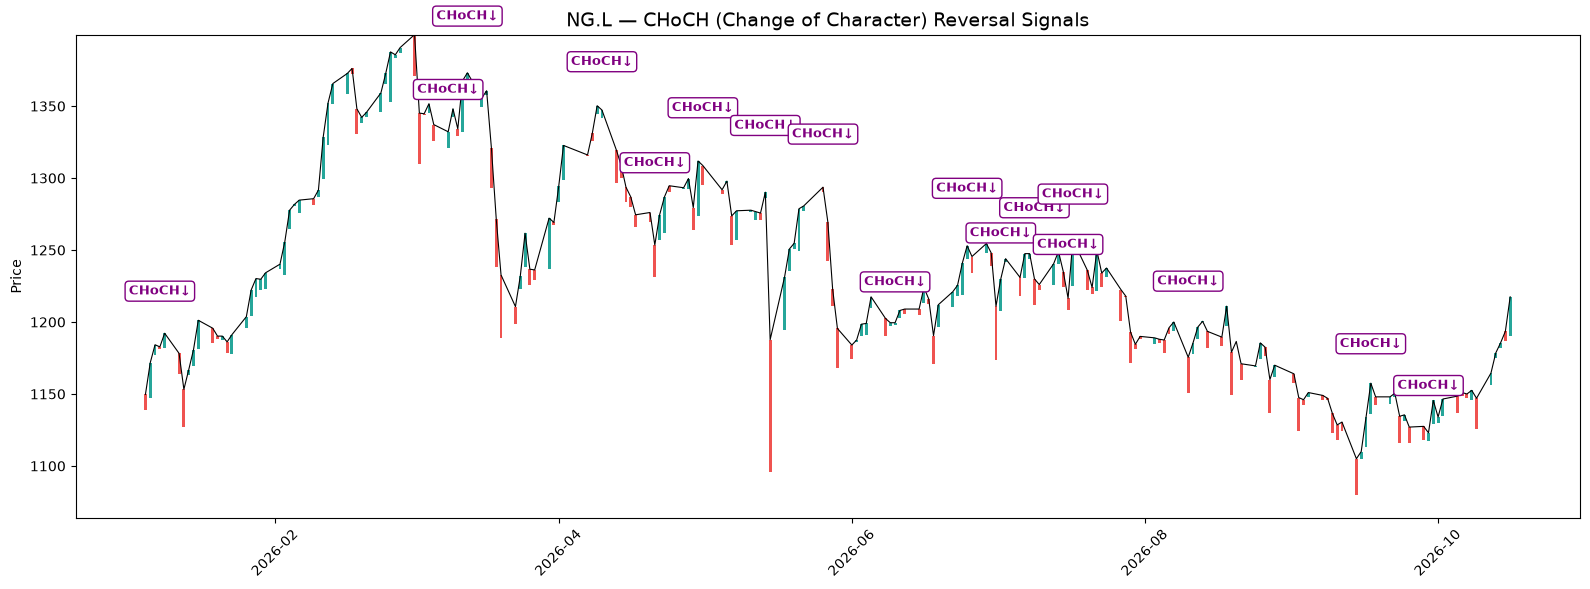

In [6]:
# ============================================================
# CELL 5 — CHoCH (Change of Character)
# ============================================================
fig, ax = make_ax()

# candlestick
d_up = d["Close"] >= d["Open"]
d_down = ~d_up
ax.bar(d.index[d_up], d["Close"][d_up] - d["Open"][d_up], 0.6,
       bottom=d["Open"][d_up], color="#26a69a")
ax.bar(d.index[d_down], d["Close"][d_down] - d["Open"][d_down], 0.6,
       bottom=d["Close"][d_down], color="#ef5350")
ax.plot(d["Close"], color="black", linewidth=0.8)

# CHoCH markers
choch_idx = d[d["ta_choch"] == 1].index
if len(choch_idx) > 0:
    for i in choch_idx:
        if d.loc[i, "ta_swing_high"] is not None:
            ax.annotate("CHoCH↓", xy=(i, d.loc[i, "High"]),
                        xytext=(0, 25), textcoords="offset points",
                        ha="center", color="purple", fontsize=9, fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="purple"))
        elif d.loc[i, "ta_swing_low"] is not None:
            ax.annotate("CHoCH↑", xy=(i, d.loc[i, "Low"]),
                        xytext=(0, -25), textcoords="offset points",
                        ha="center", color="purple", fontsize=9, fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="purple"))

ax.set_title(f"{ticker} — CHoCH (Change of Character) Reversal Signals", fontsize=14)
ax.set_ylabel("Price")
plt.tight_layout()
plt.show()

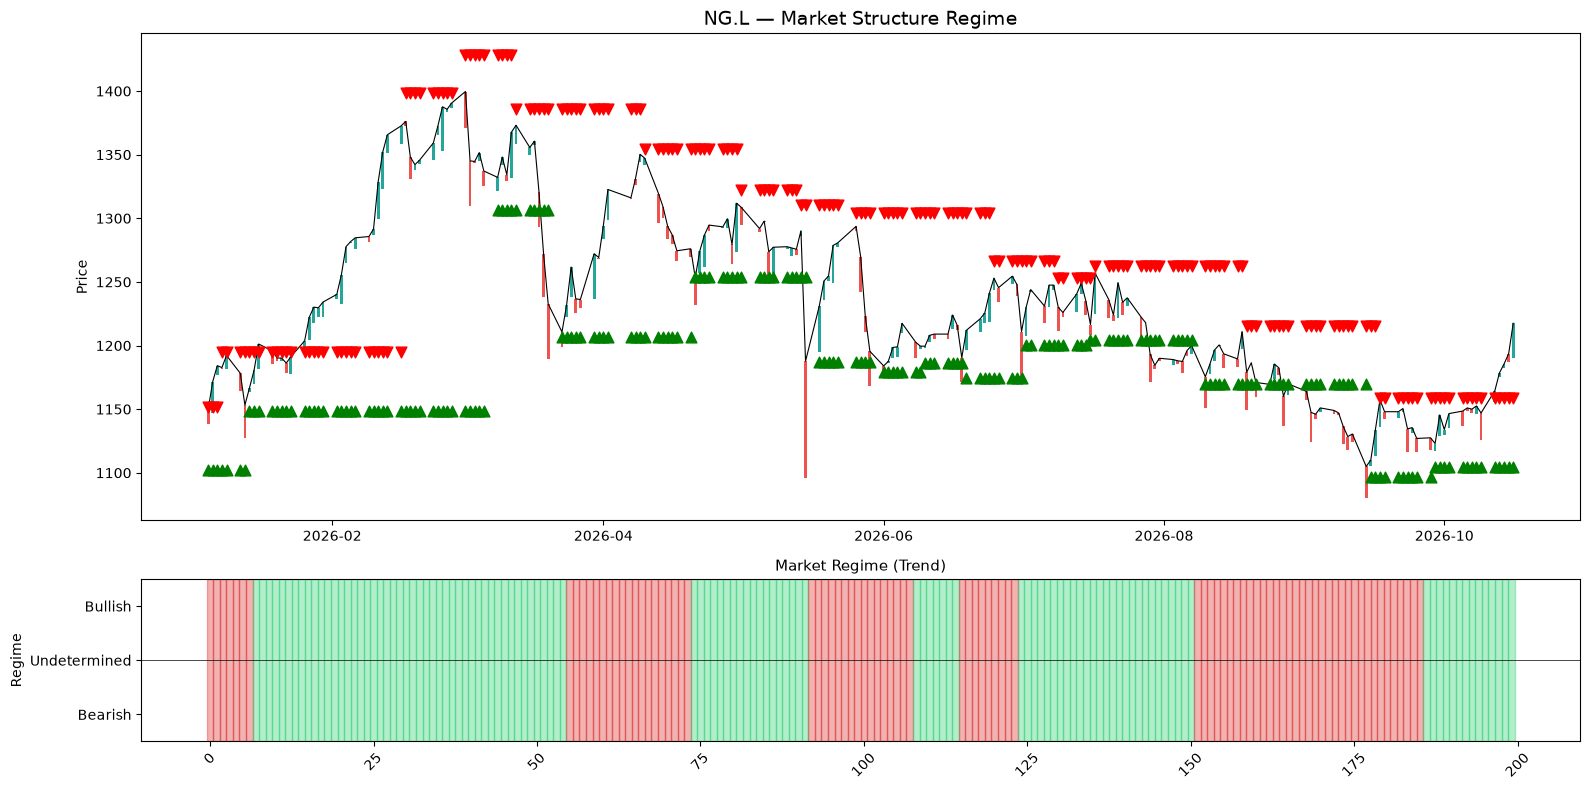

In [7]:
# ============================================================
# CELL 6 — Trend Regime (sub-plot)
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8),
                                gridspec_kw={"height_ratios": [3, 1]})

# candlestick on top
d_up = d["Close"] >= d["Open"]
d_down = ~d_up
ax1.bar(d.index[d_up], d["Close"][d_up] - d["Open"][d_up], 0.6,
        bottom=d["Open"][d_up], color="#26a69a")
ax1.bar(d.index[d_down], d["Close"][d_down] - d["Open"][d_down], 0.6,
        bottom=d["Close"][d_down], color="#ef5350")
ax1.plot(d["Close"], color="black", linewidth=0.8)

# swing points
sh = d["ta_swing_high"].notna()
if sh.any():
    ax1.scatter(d.index[sh], d["ta_swing_high"][sh], color="red", marker="v", s=60, zorder=5)
sl = d["ta_swing_low"].notna()
if sl.any():
    ax1.scatter(d.index[sl], d["ta_swing_low"][sl], color="green", marker="^", s=60, zorder=5)

# trend sub-plot
trend_colors = {1: "#00c853", -1: "#d50000", 0: "#bdbdbd"}
ax2.set_ylim(-1.5, 1.5)
for i, val in enumerate(d["ta_trend"]):
    color = trend_colors.get(val, "#bdbdbd")
    ax2.axvspan(i - 0.5, i + 0.5, color=color, alpha=0.3)
ax2.axhline(0, color="black", linewidth=0.5)
ax2.set_yticks([1, 0, -1])
ax2.set_yticklabels(["Bullish", "Undetermined", "Bearish"])
ax2.set_title("Market Regime (Trend)", fontsize=11)
ax2.set_ylabel("Regime")

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=45)
ax1.set_title(f"{ticker} — Market Structure Regime", fontsize=14)
ax1.set_ylabel("Price")
plt.tight_layout()
plt.show()

/tmp/ipykernel_15804/2692720426.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/home/gavin/Workspace/stock-market-ta-local/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


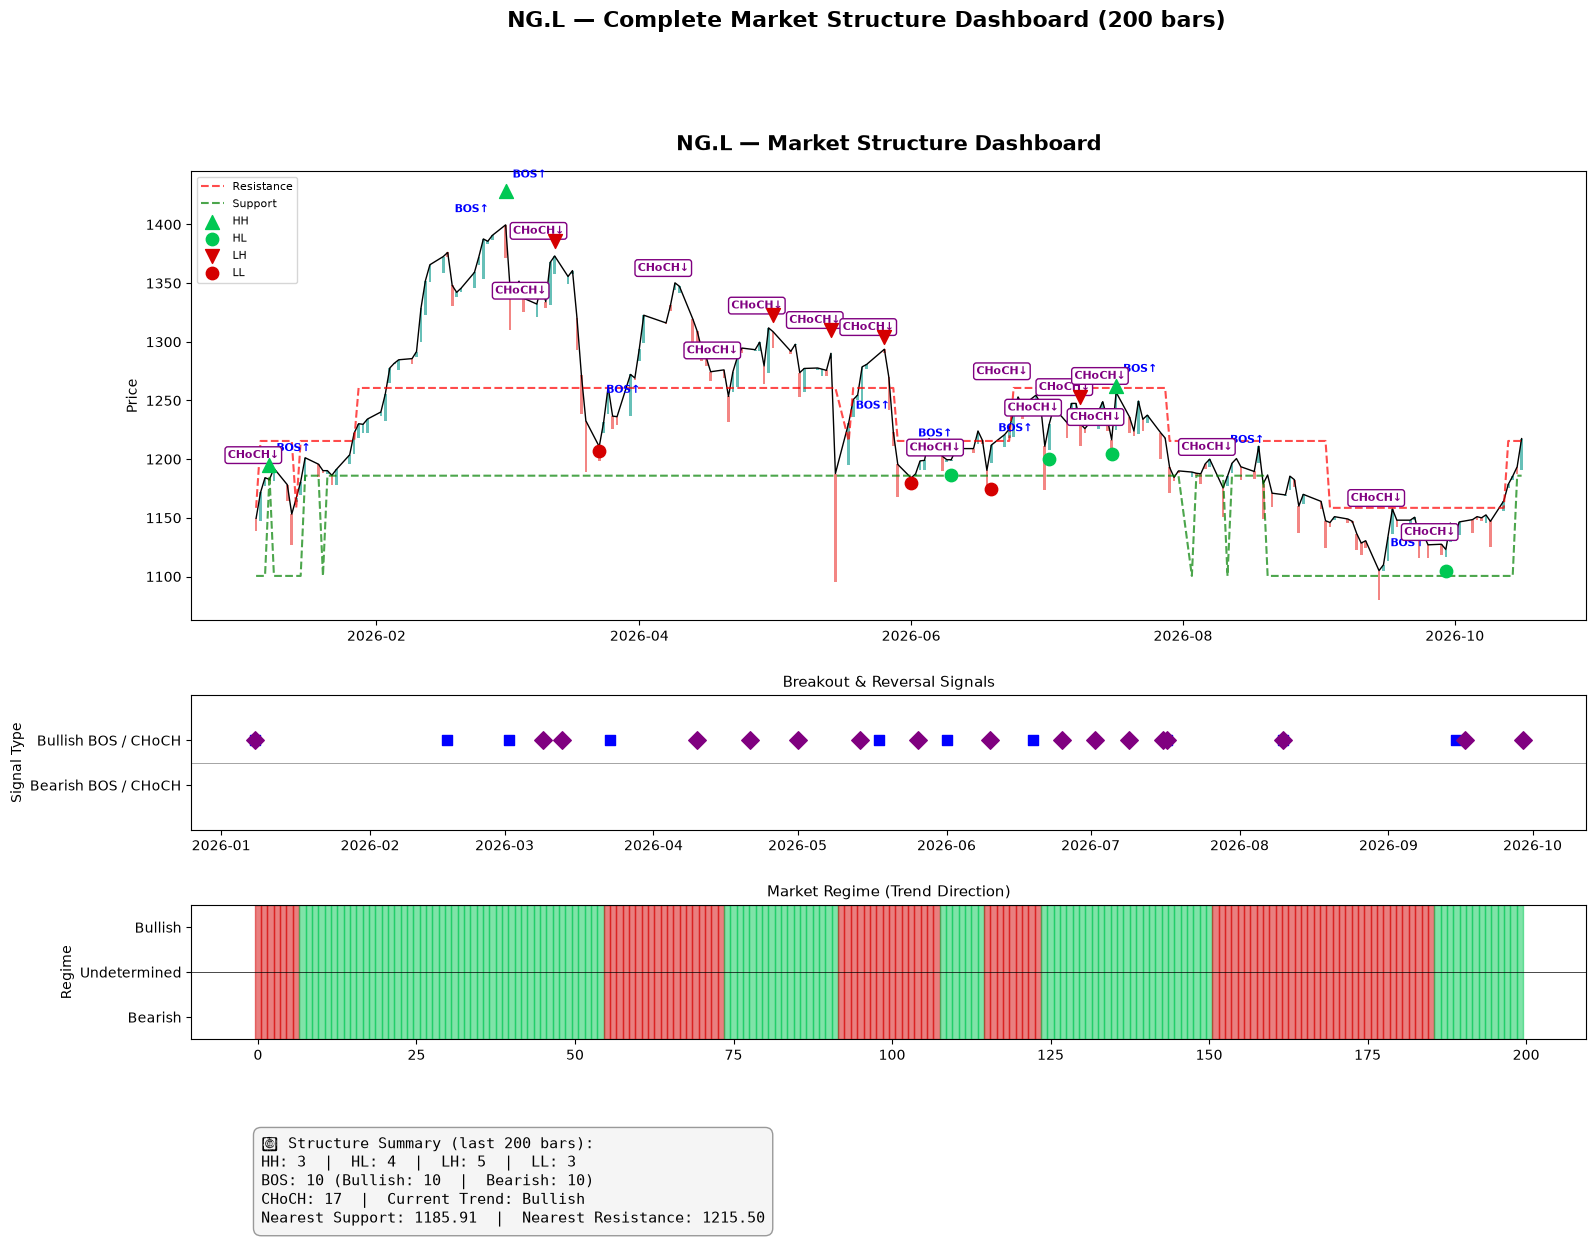

In [8]:
# ============================================================
# CELL 7 — MASTER DASHBOARD: all structure indicators combined
# ============================================================
fig = plt.figure(figsize=(18, 14))
gs = fig.add_gridspec(4, 1, height_ratios=[4, 1.2, 1.2, 1.2], hspace=0.35)

# — row 0: price + swing points + S/R + HH/HL/LH/LL —
ax_price = fig.add_subplot(gs[0])
d_up = d["Close"] >= d["Open"]
d_down = ~d_up
ax_price.bar(d.index[d_up], d["Close"][d_up] - d["Open"][d_up], 0.6,
             bottom=d["Open"][d_up], color="#26a69a", alpha=0.7)
ax_price.bar(d.index[d_down], d["Close"][d_down] - d["Open"][d_down], 0.6,
             bottom=d["Close"][d_down], color="#ef5350", alpha=0.7)
ax_price.plot(d["Close"], color="black", linewidth=1)

# S/R bands
res = d["ta_nearest_resistance"].notna()
sup = d["ta_nearest_support"].notna()
if res.any():
    ax_price.plot(d.index[res], d["ta_nearest_resistance"][res],
                  color="red", linestyle="--", linewidth=1.5, alpha=0.7, label="Resistance")
if sup.any():
    ax_price.plot(d.index[sup], d["ta_nearest_support"][sup],
                  color="green", linestyle="--", linewidth=1.5, alpha=0.7, label="Support")

# HH/HL
ax_price.scatter(d.index[d["ta_hh"]==1], d["High"][d["ta_hh"]==1],
                 color="#00c853", marker="^", s=100, zorder=5, label="HH")
ax_price.scatter(d.index[d["ta_hl"]==1], d["Low"][d["ta_hl"]==1],
                 color="#00c853", marker="o", s=80, zorder=5, label="HL")
ax_price.scatter(d.index[d["ta_lh"]==1], d["High"][d["ta_lh"]==1],
                 color="#d50000", marker="v", s=100, zorder=5, label="LH")
ax_price.scatter(d.index[d["ta_ll"]==1], d["Low"][d["ta_ll"]==1],
                 color="#d50000", marker="o", s=80, zorder=5, label="LL")

ax_price.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax_price.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_price.set_title(f"{ticker} — Market Structure Dashboard", fontsize=15, fontweight="bold", pad=15)
ax_price.legend(loc="upper left", fontsize=8)
ax_price.set_ylabel("Price")

# — row 1: BOS + CHoCH events —
ax_signals = fig.add_subplot(gs[1])
ax_price_ylim = ax_price.get_ylim()

# BOS
bos = d[d["ta_bos"] == 1]
for _, row in bos.iterrows():
    i = row.name
    if row["ta_swing_high"] is not None:
        ax_price.annotate("BOS↑", xy=(i, row["High"]),
                          xytext=(5, 10), textcoords="offset points",
                          color="blue", fontsize=8, fontweight="bold")
        ax_signals.scatter(i, 0.5, color="blue", s=60, marker="s")
    elif row["ta_swing_low"] is not None:
        ax_price.annotate("BOS↓", xy=(i, row["Low"]),
                          xytext=(5, -15), textcoords="offset points",
                          color="darkorange", fontsize=8, fontweight="bold")
        ax_signals.scatter(i, -0.5, color="darkorange", s=60, marker="s")

# CHoCH
choch = d[d["ta_choch"] == 1]
for _, row in choch.iterrows():
    i = row.name
    if row["ta_swing_high"] is not None:
        ax_price.annotate("CHoCH↓", xy=(i, row["High"]),
                          xytext=(-30, 5), textcoords="offset points",
                          color="purple", fontsize=8, fontweight="bold",
                          bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="purple"))
        ax_signals.scatter(i, 0.5, color="purple", s=80, marker="D", zorder=6)
    elif row["ta_swing_low"] is not None:
        ax_price.annotate("CHoCH↑", xy=(i, row["Low"]),
                          xytext=(-30, -15), textcoords="offset points",
                          color="purple", fontsize=8, fontweight="bold",
                          bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="purple"))
        ax_signals.scatter(i, -0.5, color="purple", s=80, marker="D", zorder=6)

ax_signals.set_ylim(-1.5, 1.5)
ax_signals.axhline(0, color="gray", linewidth=0.5)
ax_signals.set_yticks([0.5, -0.5])
ax_signals.set_yticklabels(["Bullish BOS / CHoCH", "Bearish BOS / CHoCH"])
ax_signals.set_ylabel("Signal Type")
ax_signals.set_title("Breakout & Reversal Signals", fontsize=11)

# — row 2: trend regime —
ax_trend = fig.add_subplot(gs[2])
trend_colors = {1: "#00c853", -1: "#d50000", 0: "#e0e0e0"}
for i, val in enumerate(d["ta_trend"]):
    ax_trend.axvspan(i - 0.5, i + 0.5, color=trend_colors.get(val, "#e0e0e0"), alpha=0.5)
ax_trend.axhline(0, color="black", linewidth=0.5)
ax_trend.set_ylim(-1.5, 1.5)
ax_trend.set_yticks([1, 0, -1])
ax_trend.set_yticklabels(["Bullish", "Undetermined", "Bearish"])
ax_trend.set_ylabel("Regime")
ax_trend.set_title("Market Regime (Trend Direction)", fontsize=11)

# — row 3: structure event count summary bar —
ax_summary = fig.add_subplot(gs[3])
ax_summary.axis("off")

n_hh = (d["ta_hh"] == 1).sum()
n_hl = (d["ta_hl"] == 1).sum()
n_lh = (d["ta_lh"] == 1).sum()
n_ll = (d["ta_ll"] == 1).sum()
n_bos = (d["ta_bos"] == 1).sum()
n_choch = (d["ta_choch"] == 1).sum()
bullish_bos = ((d["ta_bos"] == 1) & (d["ta_swing_high"].notna())).sum()
bearish_bos = ((d["ta_bos"] == 1) & (d["ta_swing_low"].notna())).sum()

# Format support/resistance values safely
support_val = f"{d['ta_nearest_support'].dropna().iloc[-1]:.2f}" if d['ta_nearest_support'].notna().any() else 'N/A'
resistance_val = f"{d['ta_nearest_resistance'].dropna().iloc[-1]:.2f}" if d['ta_nearest_resistance'].notna().any() else 'N/A'
summary_text = (
    f"📊 Structure Summary (last {window} bars):\n"
    f"HH: {n_hh}  |  HL: {n_hl}  |  LH: {n_lh}  |  LL: {n_ll}\n"
    f"BOS: {n_bos} (Bullish: {bullish_bos}  |  Bearish: {bearish_bos})\n"
    f"CHoCH: {n_choch}  |  Current Trend: {'Bullish' if d['ta_trend'].iloc[-1] == 1 else 'Bearish' if d['ta_trend'].iloc[-1] == -1 else 'Undetermined'}\n"
    f"Nearest Support: {support_val}  |  Nearest Resistance: {resistance_val}"
)

ax_summary.text(0.05, 0.5, summary_text, fontsize=11, family="monospace",
                verticalalignment="center",
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#f5f5f5", edgecolor="#999"))

plt.suptitle(f"{ticker} — Complete Market Structure Dashboard ({window} bars)",
             fontsize=16, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()